<a href="https://colab.research.google.com/github/cal-me-j/atf-ai-learn/blob/main/Week2_07_context_window_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.2: Context Window Management - Ready to start!')
print('\nTopics covered:')
print('  - Understanding token limits and context windows')
print('  - Token counting and estimation techniques')
print('  - Context compression strategies')
print('  - Conversation history management')
print('  - Sliding window approaches')


✅ Week 2.2: Context Window Management - Ready to start!

Topics covered:
  - Understanding token limits and context windows
  - Token counting and estimation techniques
  - Context compression strategies
  - Conversation history management
  - Sliding window approaches


---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Understanding token limits and context windows.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [7]:
# YOUR CODE HERE
# Complete the exercise following the instructions above

# Test your implementation
# Add test cases here
class TokenEstimator:
    def __init__(self, chars_per_token: float = 4.0, words_per_token: float = 0.75):
        self.chars_per_token = chars_per_token
        self.words_per_token = words_per_token

    def estimate_tokens(self, text: str) -> dict:
        if not isinstance(text, str):
            raise ValueError("Input must be a string")

        char_count = len(text)
        word_count = len(text.split())

        # Estimates
        by_char = round(char_count / self.chars_per_token)
        by_word = round(word_count / self.words_per_token)

        # Take the average for a balanced heuristic estimate
        estimated_tokens = round((by_char + by_word) / 2)

        return {
            "characters": char_count,
            "words": word_count,
            "est_tokens_by_char": max(1, by_char) if char_count > 0 else 0,
            "est_tokens_by_word": max(1, by_word) if word_count > 0 else 0,
            "final_estimate": max(1, estimated_tokens) if char_count > 0 else 0
        }

# Test implementation
estimator = TokenEstimator()
print(json.dumps(estimator.estimate_tokens("Hello world! This is a simple test."), indent=2))

pass  # Replace with your implementation

{
  "characters": 35,
  "words": 7,
  "est_tokens_by_char": 9,
  "est_tokens_by_word": 9,
  "final_estimate": 9
}


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [6]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Token counting and estimation techniques.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [8]:
# YOUR CODE HERE
# Implement the intermediate exercise
class ConversationBuffer:
    def __init__(self, estimator, max_token_limit: int = 50):
        self.estimator = estimator
        self.max_token_limit = max_token_limit
        self.history = []  # List of dicts: {"role": str, "content": str}

    def add_message(self, role: str, content: str):
        self.history.append({"role": role, "content": content})
        self._truncate_to_budget()

    def _get_total_tokens(self) -> int:
        # Estimate tokens for all messages currently in history
        total = 0
        for msg in self.history:
            # Estimate the content
            est = self.estimator.estimate_tokens(msg["content"])["final_estimate"]
            # Add a small overhead for the metadata/role structure (e.g., 3 tokens)
            total += est + 3
        return total

    def _truncate_to_budget(self):
        # Keep popping oldest messages until we fit under the maximum token limit
        while self._get_total_tokens() > self.max_token_limit and len(self.history) > 1:
            removed = self.history.pop(0)
            print(f"⚠️ Pruned oldest message to stay within budget: '{removed['content'][:20]}...'\n")

    def get_messages(self):
        return self.history

# Test implementation
buffer = ConversationBuffer(estimator=estimator, max_token_limit=30)

buffer.add_message("user", "Hi there! I need help with my project.")
buffer.add_message("assistant", "Sure! What seems to be the main issue?")
buffer.add_message("user", "It keeps running out of context memory.") # This will trigger pruning

print("Current Active History:", json.dumps(buffer.get_messages(), indent=2))

pass  # Replace with your implementation

⚠️ Pruned oldest message to stay within budget: 'Hi there! I need hel...'

Current Active History: [
  {
    "role": "assistant",
    "content": "Sure! What seems to be the main issue?"
  },
  {
    "role": "user",
    "content": "It keeps running out of context memory."
  }
]


---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

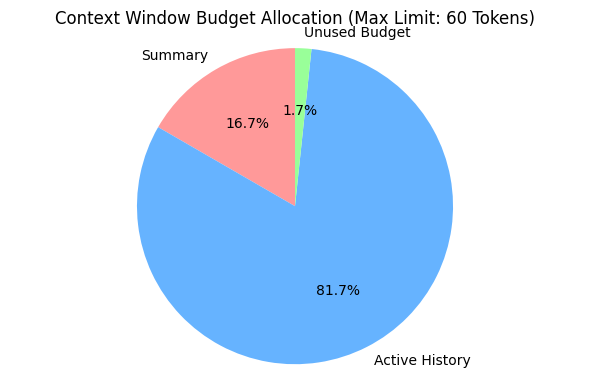

In [9]:
# YOUR CODE HERE
# Build your complete implementation

import logging
import matplotlib.pyplot as plt
import json

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger("DigitalTwinContext")

class ProductionContextManager:
    def __init__(self, estimator, max_budget: int = 100, keep_recent_count: int = 2):
        self.estimator = estimator
        self.max_budget = max_budget
        self.keep_recent_count = keep_recent_count
        self.active_history = []
        self.summary = ""
        self.log_history = []

    def add_message(self, role: str, content: str):
        self.active_history.append({"role": role, "content": content})
        logger.info(f"Added message from '{role}' ({len(content)} chars).")
        self.manage_context()

    def _get_token_usage(self) -> dict:
        summary_tokens = self.estimator.estimate_tokens(self.summary)["final_estimate"] if self.summary else 0

        active_tokens = 0
        for msg in self.active_history:
            active_tokens += self.estimator.estimate_tokens(msg["content"])["final_estimate"] + 3

        total = summary_tokens + active_tokens
        return {
            "summary_tokens": summary_tokens,
            "active_tokens": active_tokens,
            "total_tokens": total,
            "remaining_budget": max(0, self.max_budget - total)
        }

    def manage_context(self):
        usage = self._get_token_usage()
        if usage["total_tokens"] <= self.max_budget:
            return

        logger.warning(f"Budget exceeded ({usage['total_tokens']}/{self.max_budget} tokens). Initiating compression...")

        # Keep the most recent messages untouched, compress the rest
        while len(self.active_history) > self.keep_recent_count:
            compress_msg = self.active_history.pop(0)
            # Heuristic/mock compression: simulating summarizing the message
            simulated_summary_addition = f" [Summary: {compress_msg['role']} spoke about {compress_msg['content'][:15]}...]"
            self.summary += simulated_summary_addition
            logger.info(f"Compressed message to summary: '{compress_msg['content'][:15]}...'")

            # Re-check budget
            usage = self._get_token_usage()
            if usage["total_tokens"] <= self.max_budget:
                break

        # If still over budget, apply sliding window truncation to active history
        while self._get_token_usage()["total_tokens"] > self.max_budget and len(self.active_history) > 1:
            dropped = self.active_history.pop(0)
            logger.error(f"Emergency budget defense: dropped message completely: '{dropped['content'][:15]}...'")

    def visualize_buffer(self):
        usage = self._get_token_usage()
        labels = ['Summary', 'Active History', 'Unused Budget']
        sizes = [usage['summary_tokens'], usage['active_tokens'], usage['remaining_budget']]
        colors = ['#ff9999','#66b3ff','#99ff99']

        fig, ax = plt.subplots(figsize=(6, 4))
        ax.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
        ax.axis('equal')
        plt.title(f"Context Window Budget Allocation (Max Limit: {self.max_budget} Tokens)")
        plt.tight_layout()
        plt.show()

# --- Demonstration ---
manager = ProductionContextManager(estimator=estimator, max_budget=60, keep_recent_count=2)

# Simulate conversation
manager.add_message("user", "Hi! Please explain Quantum Computing in simple terms.")
manager.add_message("assistant", "Quantum computing uses qubits instead of classical bits, allowing superposition.")
manager.add_message("user", "Fascinating! How do qubits maintain coherence?")
manager.add_message("assistant", "They must be kept extremely cold to avoid environmental noise.")

# Check the managed context and visualization
manager.visualize_buffer()
# Test your production system
# Add comprehensive tests here

---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code